# Task 7: fitting the student on the MACE dataset

The student is the same shifted LJ sum over the 424 framework atoms as in task 2 (`energy_fast`), but with the eight **pair** parameters free: (ε, σ) for CH4–Zn, CH4–O, CH4–C and CH4–H. Functions in `src/fit.py`.

**Parametrisation.** The optimizer works on one flat vector of eight numbers:

```
params = [eps_Zn, eps_O, eps_C, eps_H, sigma_Zn, sigma_O, sigma_C, sigma_H]   # pair values with CH4, K and A
```

Chosen: the pair values directly, not element values with Lorentz-Berthelot behind them. Both are one-to-one, but with pair values the bounds for the optimizer are directly physical, the start values are the baseline pairs from task 2, and the fitted numbers are immediately what goes into the README. From eight numbers to the two arrays of length 424: every framework atom has an element index (Zn 0, O 1, C 2, H 3), and `params[0:4][element_index]` picks its ε for every atom.

**What to fit on?** Least squares on E weighs every point equally, but Widom and GCMC weigh every point with exp(−E/T). Hence two fits: plain (unweighted) and weighted with w = exp(−E_MACE/T_w), T_w = 1000 K (softened, so that not only the 71 deepest points count).

In [1]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.insert(0, "../src")
import time
import numpy as np
import matplotlib.pyplot as plt
from energy import load_framework, load_force_field
from widom import widom, rho_framework, henry_coefficient
from gcmc import CH4_EPS, CH4_SIGMA
from fit import (ELEMENTS, PARAM_NAMES, element_indices, baseline_params, params_to_pairs,
                 student_energies, residuals, boltzmann_weights, fit_student)

In [2]:
positions, symbols, L, masses = load_framework("../data/IRMOF-1.cif")
lj_params = load_force_field("../data/force_field/generic_dreiding_uff_mixing_rules.def")
rho_fw = rho_framework(masses, L)
T = 298.0
K_TO_KJMOL = 1 / 120.27

element_index = element_indices(symbols)
params_baseline = baseline_params(lj_params, (CH4_EPS, CH4_SIGMA))
print("params_baseline =", dict(zip(PARAM_NAMES, params_baseline.round(3))))

data = np.genfromtxt("../data/mace_dataset_irmof1_ch4.csv", delimiter=",", names=True)
dataset_positions = np.column_stack([data["x"], data["y"], data["z"]])
E_base = data["E_baseline_K"]
E_mace = data["E_mace_K"]
print(dataset_positions.shape, "positions")

params_baseline = {'eps_Zn': np.float64(99.45), 'eps_O': np.float64(87.367), 'eps_C': np.float64(87.093), 'eps_H': np.float64(34.819), 'sigma_Zn': np.float64(3.091), 'sigma_O': np.float64(3.377), 'sigma_C': np.float64(3.596), 'sigma_H': np.float64(3.283)}
(4000, 3) positions


../.venv/lib/python3.14/site-packages/ase/io/cif.py:411: UserWarning: crystal system 'cubic' is not interpreted for space group Spacegroup(225, setting=1). This may result in wrong setting!
  warnings.warn(


## Test

With `params_baseline`, `student_energies` must return the column `E_baseline_K` (that is how that column was made). The positions are stored with six decimals in the CSV; on the steep repulsive wall (E ≈ 8000 K) a shift of 1e-6 Å already gives 0.03 K difference, hence `atol=0.1`.

In [3]:
t0 = time.time()
E_check = student_energies(params_baseline, dataset_positions, positions, element_index, L)
dt = time.time() - t0
assert np.allclose(E_check, E_base, atol=0.1), np.abs(E_check - E_base).max()
print(f"test ok, 1 call with {len(E_check)} positions: {dt:.2f} s")
print(f"start cost (baseline): {0.5 * np.sum((E_base - E_mace) ** 2):.3e}, RMS {np.sqrt(np.mean((E_base - E_mace) ** 2)):.0f} K")

test ok, 1 call with 4000 positions: 0.15 s
start cost (baseline): 4.561e+09, RMS 1510 K


## Fit 1: plain (unweighted) and fit 2: weighted

In [4]:
t0 = time.time()
res_naive = fit_student(params_baseline, dataset_positions, positions, element_index, L, E_mace)
params_naive = res_naive.x
print(f"plain   : nfev {res_naive.nfev}, {res_naive.message}, {time.time() - t0:.0f} s")

T_w = 1000.0
weights = boltzmann_weights(E_mace, T_w)
t0 = time.time()
res_weighted = fit_student(params_baseline, dataset_positions, positions, element_index, L, E_mace, weights)
params_weighted = res_weighted.x
print(f"weighted: nfev {res_weighted.nfev}, {res_weighted.message}, {time.time() - t0:.0f} s")

print()
print(f"{'parameter':10s} {'baseline':>9s} {'plain':>9s} {'weighted':>9s}")
for name, b, n, w in zip(PARAM_NAMES, params_baseline, params_naive, params_weighted):
    print(f"{name:10s} {b:9.3f} {n:9.3f} {w:9.3f}")

plain   : nfev 62, `ftol` termination condition is satisfied., 71 s


weighted: nfev 36, `ftol` termination condition is satisfied., 43 s

parameter   baseline     plain  weighted
eps_Zn        99.450    67.819   108.889
eps_O         87.367   358.766   450.987
eps_C         87.093    99.313    96.503
eps_H         34.819     0.100     0.100
sigma_Zn       3.091     3.728     3.916
sigma_O        3.377     2.974     2.934
sigma_C        3.596     3.474     3.443
sigma_H        3.283     4.350     4.243


In [5]:
E_naive = student_energies(params_naive, dataset_positions, positions, element_index, L)
E_weighted = student_energies(params_weighted, dataset_positions, positions, element_index, L)

attractive = E_base < 0
deep = E_mace * K_TO_KJMOL < -20
models = {"baseline": E_base, "student plain": E_naive, "student weighted": E_weighted}
print(f"{'':16s} {'<exp(-E/T)>':>12s} {'RMS all [K]':>13s} {'RMS attractive':>15s} {'RMS deep (<-20)':>16s} {'min [kJ/mol]':>13s}")
for name, E in models.items():
    r = E - E_mace
    print(f"{name:16s} {np.mean(np.exp(-E / T)):12.1f} {np.sqrt(np.mean(r ** 2)):13.0f} {np.sqrt(np.mean(r[attractive] ** 2)):15.0f} "
          f"{np.sqrt(np.mean(r[deep] ** 2)):16.0f} {E.min() * K_TO_KJMOL:13.1f}")
print(f"{'MACE':16s} {np.mean(np.exp(-E_mace / T)):12.1f} {'':>13s} {'':>15s} {'':>16s} {E_mace.min() * K_TO_KJMOL:13.1f}")
print(f"\n(number of points: {len(E_mace)} total, {attractive.sum()} attractive, {deep.sum()} deep)")

                  <exp(-E/T)>   RMS all [K]  RMS attractive  RMS deep (<-20)  min [kJ/mol]
baseline                 10.2          1510             462             1539         -13.9
student plain           118.4           479             218              531         -25.6
student weighted        310.8           624             216              289         -26.8
MACE                    378.9                                                        -29.9

(number of points: 4000 total, 3291 attractive, 71 deep)


## Parity plot and residuals

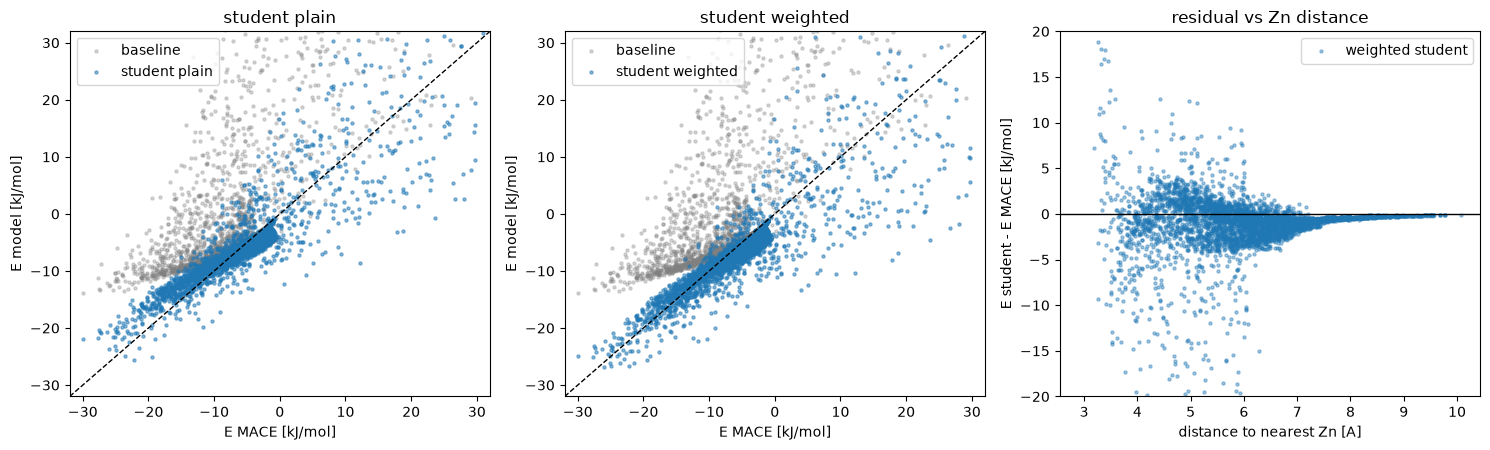

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
lim = [-32, 32]
for ax, (name, E) in zip(axes[:2], [("student plain", E_naive), ("student weighted", E_weighted)]):
    ax.scatter(E_mace * K_TO_KJMOL, E_base * K_TO_KJMOL, s=5, alpha=0.3, color="gray", label="baseline")
    ax.scatter(E_mace * K_TO_KJMOL, E * K_TO_KJMOL, s=5, alpha=0.5, label=name)
    ax.plot(lim, lim, "k--", lw=1)
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel("E MACE [kJ/mol]"); ax.set_ylabel("E model [kJ/mol]")
    ax.set_title(name); ax.legend(loc="upper left")

# residual against the distance to the nearest Zn
from energy import distances_to_framework
zn_positions = positions[np.array(symbols) == "Zn"]
d_zn = np.array([distances_to_framework(zn_positions, p, L).min() for p in dataset_positions])
ax = axes[2]
ax.scatter(d_zn, (E_weighted - E_mace) * K_TO_KJMOL, s=5, alpha=0.4, label="weighted student")
ax.axhline(0, color="k", lw=1)
ax.set_ylim(-20, 20)
ax.set_xlabel("distance to nearest Zn [A]"); ax.set_ylabel("E student - E MACE [kJ/mol]")
ax.set_title("residual vs Zn distance"); ax.legend()
fig.tight_layout()
fig.savefig("../results/student_parity.png", dpi=150)

## K_H: baseline, student and MACE side by side

Student and baseline via Widom with 100,000 fresh insertions (seed 100, as in notebook 03). MACE via Widom directly on the dataset (notebook 06; overlaps count as exp(−E/T) = 0).

In [7]:
def widom_K_H(params, seed=100, N=100_000):
    eps_pair, sigma_pair = params_to_pairs(params, element_index)
    rng = np.random.default_rng(seed)
    bm, sem = widom(N, T, positions, eps_pair, sigma_pair, L, rng)
    return bm, sem, henry_coefficient(bm, T, rho_fw), henry_coefficient(sem, T, rho_fw)

K_H_mace, K_H_mace_sem = 1.442e-4, 0.20e-4   # notebook 06
rows = [("baseline DREIDING/UFF", *widom_K_H(params_baseline)),
        ("student plain", *widom_K_H(params_naive)),
        ("student weighted", *widom_K_H(params_weighted))]
print(f"{'model':24s} {'<exp(-U/T)>':>16s} {'K_H [mol/kg/Pa]':>22s} {'x baseline':>11s} {'/ MACE':>7s}")
K_H_base = rows[0][3]
for name, bm, sem, kh, kh_sem in rows:
    print(f"{name:24s} {bm:9.3f} +- {sem:5.3f} {kh:11.3e} +- {kh_sem:8.1e} {kh / K_H_base:11.1f} {kh / K_H_mace:7.2f}")
print(f"{'MACE-MP-0 + D3':24s} {'':>16s} {K_H_mace:11.3e} +- {K_H_mace_sem:8.1e} {K_H_mace / K_H_base:11.1f} {'1.00':>7s}")
np.savetxt("../results/student_params.csv", np.column_stack([params_baseline, params_naive, params_weighted]),
           delimiter=",", header="baseline,naive,weighted  (rows: " + ",".join(PARAM_NAMES) + ")", comments="# ", fmt="%.4f")

model                         <exp(-U/T)>        K_H [mol/kg/Pa]  x baseline  / MACE
baseline DREIDING/UFF        5.634 +- 0.027   3.832e-06 +-  1.8e-08         1.0    0.03
student plain               52.746 +- 1.439   3.588e-05 +-  9.8e-07         9.4    0.25
student weighted           133.578 +- 3.362   9.087e-05 +-  2.3e-06        23.7    0.63
MACE-MP-0 + D3                              1.442e-04 +-  2.0e-05        37.6    1.00


## Findings

- **The weighted fit is the right student.** On all points together it is worse than the plain fit (higher RMS), but on the deep wells, which determine ⟨exp(−E/T)⟩ and hence K_H, it is almost twice as good. That is the effect of the weighting: 77% of the plain cost sat in 325 repulsive points that GCMC never visits.
- **K_H**: baseline 3.8e-6, weighted student ≈ 9e-5, MACE 1.4e-4 mol/kg/Pa. On a log scale the student closes most of the gap (student/MACE ≈ 0.6).
- **ε_H runs to the lower bound** in both fits. The optimizer switches hydrogen off and compensates with a much deeper and smaller O well (ε_O ≈ 4× baseline, smaller σ_O). The student effectively has six parameters; ε and σ of one pair are strongly correlated and H contributes little.
- **The student scores better on the dataset than on fresh Widom points** (ratio student/MACE 0.82 on the dataset, 0.63 via Widom). That is overfitting in the weak sense: the weighting lets 71 deep points dominate, and the eight parameters partly adapt to those specific points. A larger dataset or targeted sampling of the deep regions (e.g. active learning on large residuals) is the obvious next step.
- **Where the student fails**: see the residual plot against the Zn distance. Beyond 7 Å from a Zn the student is almost exact; within 3 to 6 Å, around the Zn4O corners where MACE has its deepest wells, the residual spreads to ±20 kJ/mol in both directions. One LJ sphere per pair cannot follow the shape and the orientation dependence of the MACE well there (the dataset has all-atom CH4, the student only sees the C atom).
- Cost: one fit ≈ 1 minute (36 to 62 function evaluations, each with eight extra calls for the numerical Jacobian); vectorising was not needed.